# Week 4 Major Project: Heart Disease Prediction Using Machine Learning

## 1. Introduction

Heart disease is one of the major health concerns worldwide. Machine learning techniques can help analyze medical data and identify patterns associated with the presence of heart disease.

In this project, we will develop and evaluate machine learning classification models using the Heart Disease UCI dataset.

We will use two supervised machine learning algorithms:

1. Logistic Regression
2. Decision Tree Classifier

The project includes data cleaning, exploratory data analysis (EDA), feature preprocessing, model training, model evaluation, and visualization.

### Project Objectives

- Load and understand the Heart Disease UCI dataset.
- Identify and handle missing values.
- Perform exploratory data analysis using graphs.
- Prepare numerical and categorical features for machine learning.
- Train Logistic Regression and Decision Tree models.
- Evaluate the models using accuracy, precision, recall, and F1-score.
- Visualize confusion matrices and ROC curves.
- Compare the models and identify the better-performing model.

### Expected Outcome

Build a binary classification model that predicts whether a record indicates the presence or absence of heart disease.

**Important:** This is an educational machine learning project, not a medical diagnostic tool.

In [4]:
# Import libraries for data handling
import os
import numpy as np
import pandas as pd

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for splitting and preprocessing data
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Import model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

# Set display options
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Dataset

The Heart Disease UCI dataset contains patient-related attributes that can be used to study patterns associated with heart disease.

In this step, we will load the dataset into a Pandas DataFrame using its original filename, `heart_disease_uci.csv`.

We will then examine the number of records, number of features, column names, and first five rows.

This initial inspection will help us understand the structure of the dataset before performing data cleaning and preprocessing.

In [6]:
df = pd.read_csv("heart_disease_uci.csv")
print("Dataset loaded successfully!")

# Display the first five records
display(df.head())

# Display all column names
print("\nDataset columns:")
print(df.columns.tolist())

Dataset loaded successfully!


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0



Dataset columns:
['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


## 3. Dataset Information

In this step, we will check the dataset's column names, data types, and non-null values to understand its structure.

In [7]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (920, 16)
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


## 4. Checking Missing Values

We count the missing values in each column to identify data that needs cleaning.

In [8]:
print(df.isnull().sum())

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


## 5. Checking Duplicate Records

Duplicate rows may affect model performance. We will check how many duplicate records exist before deciding how to handle them.

In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## 6. Statistical Summary

We use descriptive statistics to understand the distribution of numerical features, including their mean, minimum, maximum, and standard deviation.

In [10]:
display(df.describe())

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


## 7. Understanding the Target Variable

The target column `num` represents the presence and severity of heart disease. We will examine the frequency of each value before converting it into a binary classification target.## 7. Understanding the Target Variable

The target column `num` represents the presence and severity of heart disease. We will examine the frequency of each value before converting it into a binary classification target.

In [11]:
print(df["num"].value_counts().sort_index())

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64


## 8. Visualizing the Target Variable

We visualize the distribution of the original target values to understand how many records belong to each heart disease category.

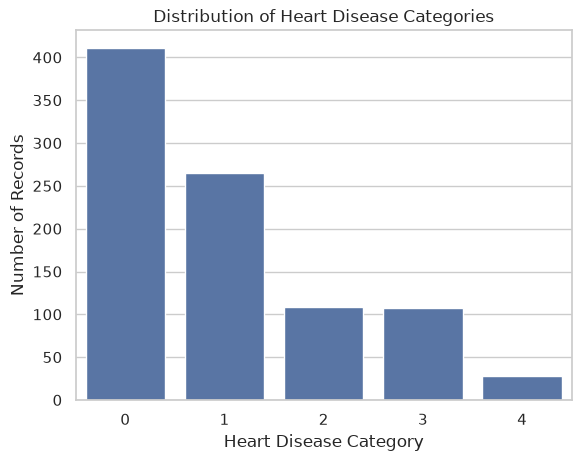

In [12]:
sns.countplot(data=df, x="num")
plt.title("Distribution of Heart Disease Categories")
plt.xlabel("Heart Disease Category")
plt.ylabel("Number of Records")
plt.show()

## 9. Creating a Binary Target Variable

The original `num` column contains values from 0 to 4. We convert it into two classes: 0 means no heart disease, while values greater than 0 mean heart disease is present.

This binary target will be used to train our classification models.

In [13]:
df["target"] = (df["num"] > 0).astype(int)

print(df["target"].value_counts())

target
1    509
0    411
Name: count, dtype: int64


## 10. Removing Unnecessary Columns

We remove the record ID, dataset source, and original target column. The new `target` column will be used for prediction.

In [14]:
df = df.drop(columns=["id", "dataset", "num"])

print("Updated shape:", df.shape)
display(df.head())

Updated shape: (920, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,target
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,67,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,1
2,67,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,37,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,41,Female,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## 11. Checking Duplicate Records

We check whether any duplicate rows exist in the cleaned dataset before continuing with data preprocessing.

In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 2


## 12. Missing Values After Target Preparation

We check missing values in the features and target column. Missing feature values will be handled during preprocessing, while the target must not contain missing values.

In [16]:
print(df.isnull().sum())

age           0
sex           0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
target        0
dtype: int64


## 13. Separating Features and Target

The input features (`X`) contain the patient attributes used for prediction. The target (`y`) contains the binary outcome: 0 for no heart disease and 1 for heart disease.

In [17]:
X = df.drop(columns="target")
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (920, 13)
Target shape: (920,)


## 14. Splitting the Dataset

We split the dataset into 80% training data and 20% testing data. Stratification preserves the proportion of both target classes in each set.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (736, 13)
Testing data: (184, 13)


## 15. Preparing Numerical and Categorical Features

The dataset contains both numerical and categorical features. We will identify these columns so that missing values, categorical encoding, and feature scaling can be handled appropriately.

This preprocessing will be fitted only on the training data to prevent data leakage.

In [19]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

print("Numerical features:", list(num_cols))
print("Categorical features:", list(cat_cols))

Numerical features: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


## 16. Data Preprocessing

We handle missing values using median imputation for numerical features and most-frequent imputation for categorical features. We scale numerical features and encode categorical features using One-Hot Encoding.

A separate preprocessing pipeline is created for each model to prevent unintended sharing of fitted preprocessing objects.

In [20]:
def create_preprocessor():
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols)
    ])

print("Preprocessing setup completed!")

Preprocessing setup completed!


## 17. Building Machine Learning Models

We create two classification pipelines: Logistic Regression and Decision Tree. Each pipeline includes preprocessing, so missing-value handling, encoding, and scaling are applied consistently during training and prediction.

In [21]:
lr_model = Pipeline([
    ("preprocessing", create_preprocessor()),
    ("model", LogisticRegression(max_iter=1000))
])

dt_model = Pipeline([
    ("preprocessing", create_preprocessor()),
    ("model", DecisionTreeClassifier(random_state=42))
])

print("Both models are ready!")

Both models are ready!


## 18. Training the Models

We train both models using the training dataset. The models learn patterns between patient features and the binary heart disease target.

In [22]:
lr_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


## 19. Making Predictions

We use the trained models to predict heart disease outcomes for the unseen testing dataset. We also obtain prediction probabilities for ROC-AUC evaluation.

In [23]:
lr_pred = lr_model.predict(X_test)
dt_pred = dt_model.predict(X_test)

lr_prob = lr_model.predict_proba(X_test)[:, 1]
dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


## 20. Model Evaluation

We evaluate both classifiers using accuracy, precision, recall, and F1-score. These metrics help us compare overall performance and how effectively each model identifies the positive class.

In [24]:
def evaluate_model(name, actual, predicted):
    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(actual, predicted), 3))
    print("Precision:", round(precision_score(actual, predicted, zero_division=0), 3))
    print("Recall:", round(recall_score(actual, predicted, zero_division=0), 3))
    print("F1-score:", round(f1_score(actual, predicted, zero_division=0), 3))

evaluate_model("Logistic Regression", y_test, lr_pred)
evaluate_model("Decision Tree", y_test, dt_pred)


Logistic Regression
Accuracy: 0.842
Precision: 0.841
Recall: 0.882
F1-score: 0.861

Decision Tree
Accuracy: 0.755
Precision: 0.771
Recall: 0.794
F1-score: 0.783


## 21. Confusion Matrix Visualization

A confusion matrix compares actual and predicted classes. It shows true positives, true negatives, false positives, and false negatives for each model.

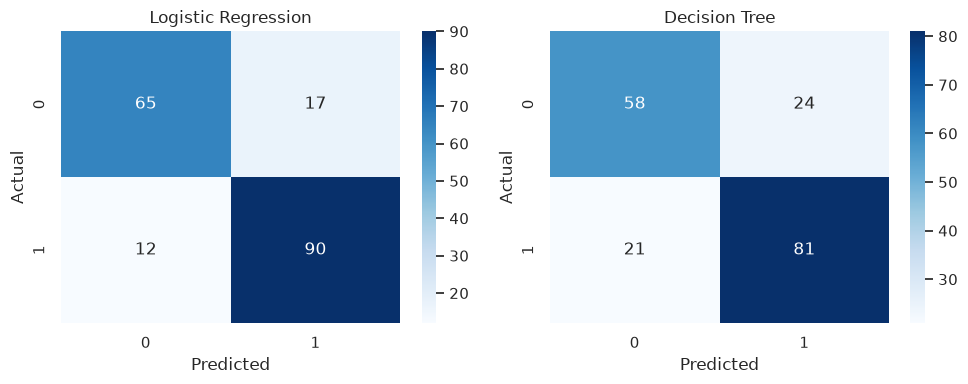

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, pred, name in zip(
    axes, [lr_pred, dt_pred], ["Logistic Regression", "Decision Tree"]
):
    sns.heatmap(
        confusion_matrix(y_test, pred),
        annot=True, fmt="d", cmap="Blues", ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 22. ROC Curve and AUC

The ROC curve illustrates the trade-off between the true positive rate and false positive rate at different classification thresholds. The Area Under the Curve (AUC) summarizes how well the model separates the two classes.

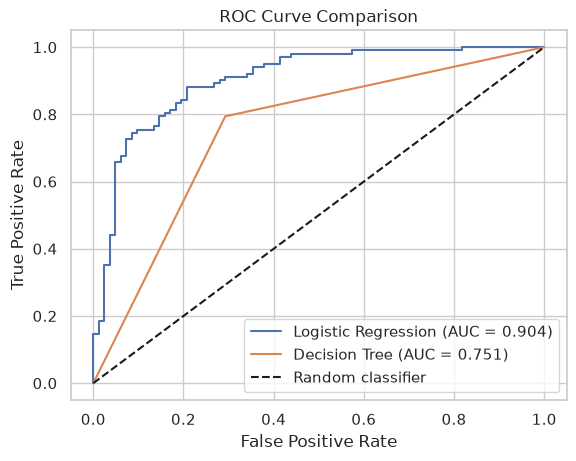

In [26]:
for name, probabilities in [
    ("Logistic Regression", lr_prob),
    ("Decision Tree", dt_prob)
]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

## 23. Comparing Model Performance

We create a comparison table containing accuracy, precision, recall, F1-score, and ROC-AUC for both models. This makes their performance easier to compare.

In [27]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, dt_pred)
    ],
    "Precision": [
        precision_score(y_test, lr_pred, zero_division=0),
        precision_score(y_test, dt_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_pred, zero_division=0),
        recall_score(y_test, dt_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, lr_pred, zero_division=0),
        f1_score(y_test, dt_pred, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, lr_prob),
        roc_auc_score(y_test, dt_prob)
    ]
})

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.842,0.841,0.882,0.861,0.904
1,Decision Tree,0.755,0.771,0.794,0.783,0.751


In [28]:
best_model = results.loc[results["F1-score"].idxmax()]

print("Best model based on F1-score:", best_model["Model"])
print("F1-score:", round(best_model["F1-score"], 3))

Best model based on F1-score: Logistic Regression
F1-score: 0.861


## 24. Final Model Results

We review the model comparison table to identify the performance of Logistic Regression and Decision Tree using the test dataset. The results will be used in the project documentation and presentation.

In [29]:
display(results.round(3))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.842,0.841,0.882,0.861,0.904
1,Decision Tree,0.755,0.771,0.794,0.783,0.751


## Conclusion

In this project, we developed a Heart Disease Prediction system using the UCI Heart Disease dataset. The dataset was cleaned by handling missing values, and categorical and numerical features were preprocessed using imputation, one-hot encoding, and feature scaling.

Two machine-learning models, Logistic Regression and Decision Tree, were trained and evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

Logistic Regression performed better than Decision Tree across all five evaluation metrics, achieving an accuracy of **84.2%**, an F1-score of **86.1%**, and a ROC-AUC of **0.904**. Therefore, Logistic Regression was selected as the best-performing model for this experiment.

This project demonstrates how machine learning can be used to explore patterns associated with heart disease. The results are based on the available dataset and should not be used as a substitute for professional medical diagnosis.